In [3]:
# CELL 2 — Import libraries and define parameters
# Bu cell bütün kitabxanaları aktivləşdirir və dataset parametrlərini təyin edir.

import requests
import gzip
import io
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from Bio import SeqIO
from IPython.display import display

warnings.filterwarnings("ignore")

ACCESSION = "ERR15159018"
N_READS = 10_000

sns.set_theme(style="whitegrid", context="notebook")

print("Libraries imported successfully.")
print("Dataset:", ACCESSION)
print("Target reads:", N_READS)

Libraries imported successfully.
Dataset: ERR15159018
Target reads: 10000


In [4]:
# CELL 3 — Retrieve real RNA-seq metadata from ENA
# Bu cell ENA API vasitəsilə dataset-in FASTQ ünvanlarını və metadata məlumatlarını əldə edir.

api = "https://www.ebi.ac.uk/ena/portal/api/filereport"

params = {
    "accession": ACCESSION,
    "result": "read_run",
    "fields": "run_accession,library_layout,read_count,fastq_ftp,fastq_bytes",
    "format": "json"
}

response = requests.get(api, params=params, timeout=60)
response.raise_for_status()

metadata = response.json()

if not metadata:
    raise ValueError(
        "ENA məlumat qaytarmadı. Accession nömrəsini yoxla."
    )

sample = metadata[0]

display(pd.DataFrame([sample]))

print("Metadata successfully retrieved.")

,run_accession,library_layout,read_count,fastq_ftp,fastq_bytes
0,ERR15159018,PAIRED,21670212,ftp.sra.ebi.ac.uk/vol1/fastq/ERR151/018/ERR151...,567113718;594743430


Metadata successfully retrieved.


In [5]:
# CELL 4 — Extract and validate FASTQ URLs
# Bu cell ENA-dan gələn FASTQ linklərini hazırlayır.
# Paired-end dataset olduqda iki FASTQ linki gözlənilir.

fastq_field = sample.get("fastq_ftp")

if not fastq_field:
    raise ValueError(
        "ENA fastq_ftp məlumatını qaytarmadı. "
        "Bu accession üçün FASTQ faylları ENA-da mövcud olmaya bilər."
    )

fastq_urls = [
    "https://" + x.strip().lstrip("/")
    for x in fastq_field.split(";")
    if x.strip()
]

if not fastq_urls:
    raise ValueError("FASTQ URL tapılmadı.")

print("FASTQ files found:", len(fastq_urls))

for i, url in enumerate(fastq_urls, start=1):
    print(f"FASTQ {i}: {url}")

print("\nLibrary layout:", sample.get("library_layout"))

FASTQ files found: 2
FASTQ 1: https://ftp.sra.ebi.ac.uk/vol1/fastq/ERR151/018/ERR15159018/ERR15159018_1.fastq.gz
FASTQ 2: https://ftp.sra.ebi.ac.uk/vol1/fastq/ERR151/018/ERR15159018/ERR15159018_2.fastq.gz

Library layout: PAIRED


In [6]:
# CELL 5 — Stream FASTQ reads from ENA
# Bu cell FASTQ faylını kompüterə tam yükləmədən oxuyur.
# Yalnız ilk 10 000 read RAM-a alınır.
# response.raw.decode_content=False gzip oxunması ilə bağlı mümkün problemi aradan qaldırır.

def read_fastq_stream(url, n_reads=10000):

    records = []

    with requests.get(
        url,
        stream=True,
        timeout=(30, 180)
    ) as response:

        response.raise_for_status()

        response.raw.decode_content = False

        with gzip.GzipFile(
            fileobj=response.raw,
            mode="rb"
        ) as gz:

            with io.TextIOWrapper(
                gz,
                encoding="utf-8"
            ) as handle:

                for record in SeqIO.parse(handle, "fastq"):

                    records.append(record)

                    if len(records) >= n_reads:
                        break

    return records


records = read_fastq_stream(
    fastq_urls[0],
    N_READS
)

if not records:
    raise ValueError("FASTQ faylından read oxunmadı.")

print("Successfully read:", len(records))
print("First read ID:", records[0].id)
print("First read length:", len(records[0].seq))
print("First read sequence:", str(records[0].seq)[:100])

Successfully read: 10000
First read ID: ERR15159018.1
First read length: 101
First read sequence: CGGGGTTGAGGGATAGGAGGAGAATGGGGGATAGGTGTATGAACATGAGGGTGTTTTCTCGTGTGAATGAGGGTTTTATGTTGTTAATGTGGTGGGTGAG


In [7]:
# CELL 6 — Extract sequence and Phred quality information
# Bu cell hər read üçün nucleotide sequence və Phred quality score məlumatlarını çıxarır.

sequences = [str(r.seq).upper() for r in records]

qualities = [
    np.asarray(r.letter_annotations["phred_quality"], dtype=float)
    for r in records
]

lengths = np.array([len(s) for s in sequences])

if any(len(q) != len(s) for q, s in zip(qualities, sequences)):
    raise ValueError("Sequence və quality uzunluqları uyğun gəlmir.")

all_q = np.concatenate(qualities)

mean_q = np.array([
    q.mean() if len(q) else np.nan
    for q in qualities
])

gc_percent = np.array([
    100 * (s.count("G") + s.count("C")) /
    max(1, sum(s.count(b) for b in "ATGC"))
    for s in sequences
])

n_percent = np.array([
    100 * s.count("N") / max(1, len(s))
    for s in sequences
])

print("Sequence and quality data prepared.")
print("Total bases:", lengths.sum())
print("Total quality scores:", len(all_q))

Sequence and quality data prepared.
Total bases: 1010000
Total quality scores: 1010000


In [8]:
# CELL 7 — Calculate quality control metrics
# Bu cell read uzunluğu, Phred score, Q20, Q30, GC və N content göstəricilərini hesablayır.

summary = pd.DataFrame({
    "Metric": [
        "Analyzed reads",
        "Total bases",
        "Mean read length",
        "Minimum read length",
        "Maximum read length",
        "Mean Phred score",
        "Q20 bases (%)",
        "Q30 bases (%)",
        "Mean GC content (%)",
        "Mean N content (%)"
    ],

    "Value": [
        len(records),
        int(lengths.sum()),
        round(lengths.mean(), 2),
        int(lengths.min()),
        int(lengths.max()),
        round(all_q.mean(), 2),
        round(100 * np.mean(all_q >= 20), 2),
        round(100 * np.mean(all_q >= 30), 2),
        round(gc_percent.mean(), 2),
        round(n_percent.mean(), 4)
    ]
})

display(summary)

,Metric,Value
0,Analyzed reads,1.000000e+04
1,Total bases,1.010000e+06
2,Mean read length,1.010000e+02
3,Minimum read length,1.010000e+02
4,Maximum read length,1.010000e+02
5,Mean Phred score,3.606000e+01
6,Q20 bases (%),9.801000e+01
7,Q30 bases (%),9.452000e+01
8,Mean GC content (%),5.110000e+01
9,Mean N content (%),1.460000e-02


In [9]:
# CELL 8 — Calculate per-base quality profiles
# Bu cell hər nucleotide mövqeyi üzrə orta Phred score və 25-75 percentile intervalını hesablayır.

max_len = int(lengths.max())

quality_matrix = np.full(
    (len(records), max_len),
    np.nan
)

for i, q in enumerate(qualities):
    quality_matrix[i, :len(q)] = q

positions = np.arange(1, max_len + 1)

mean_position_q = np.nanmean(quality_matrix, axis=0)

q25 = np.nanpercentile(
    quality_matrix,
    25,
    axis=0
)

q75 = np.nanpercentile(
    quality_matrix,
    75,
    axis=0
)

print("Per-base quality profile calculated.")

Per-base quality profile calculated.


In [10]:
# CELL 9 — Calculate nucleotide composition by position
# Bu cell hər mövqedə A, T, G və C nukleotidlərinin faizini hesablayır.

base_composition = {}

for base in "ATGC":

    base_composition[base] = [
        np.mean([
            sequence[pos] == base
            for sequence in sequences
            if len(sequence) > pos
        ]) if any(len(sequence) > pos for sequence in sequences)
        else np.nan

        for pos in range(max_len)
    ]

base_df = pd.DataFrame(
    base_composition,
    index=positions
)

display(base_df.head())

,A,T,G,C
1,0.0853,0.1020,0.3799,0.4201
2,0.1230,0.3412,0.2414,0.2926
3,0.1310,0.2089,0.2367,0.4234
4,0.2047,0.2223,0.2674,0.3056
5,0.2389,0.2511,0.2914,0.2186


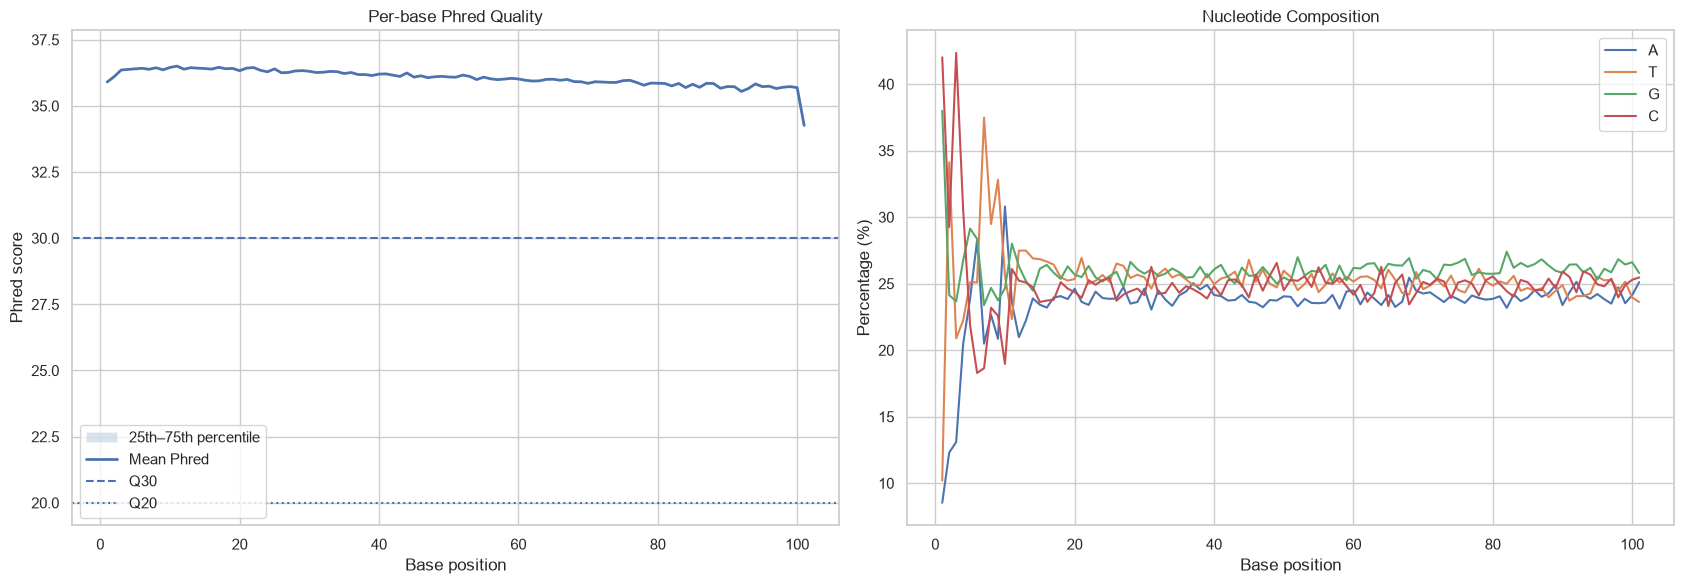

In [11]:
# CELL 10 — Plot per-base quality and nucleotide composition
# Bu cell hər mövqedə sequencing keyfiyyətini və nucleotide paylanmasını vizuallaşdırır.

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# A. Per-base Phred quality
axes[0].fill_between(
    positions,
    q25,
    q75,
    alpha=0.2,
    label="25th–75th percentile"
)

axes[0].plot(
    positions,
    mean_position_q,
    linewidth=2,
    label="Mean Phred"
)

axes[0].axhline(30, linestyle="--", label="Q30")
axes[0].axhline(20, linestyle=":", label="Q20")

axes[0].set_title("Per-base Phred Quality")
axes[0].set_xlabel("Base position")
axes[0].set_ylabel("Phred score")
axes[0].legend()

# B. Nucleotide composition
for base in "ATGC":
    axes[1].plot(
        positions,
        base_df[base] * 100,
        label=base
    )

axes[1].set_title("Nucleotide Composition")
axes[1].set_xlabel("Base position")
axes[1].set_ylabel("Percentage (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

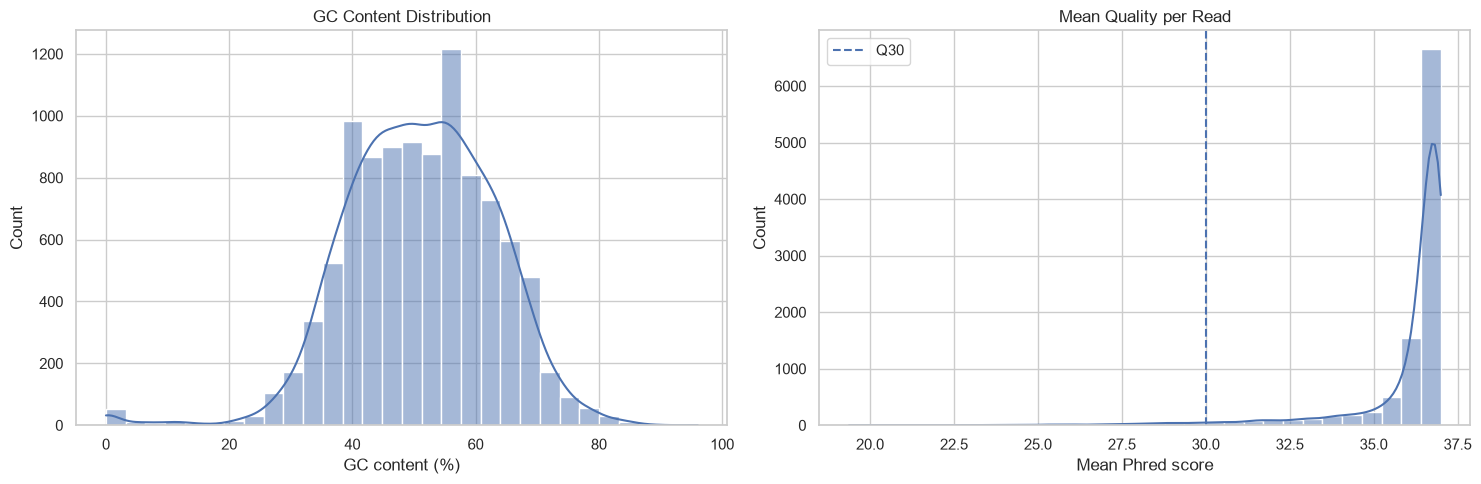

In [12]:
# CELL 11 — Visualize GC content and read quality distributions
# Bu cell read-lər üzrə GC content və orta Phred score paylanmasını göstərir.

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    gc_percent,
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("GC Content Distribution")
axes[0].set_xlabel("GC content (%)")

sns.histplot(
    mean_q,
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].axvline(
    30,
    linestyle="--",
    label="Q30"
)

axes[1].set_title("Mean Quality per Read")
axes[1].set_xlabel("Mean Phred score")
axes[1].legend()

plt.tight_layout()
plt.show()

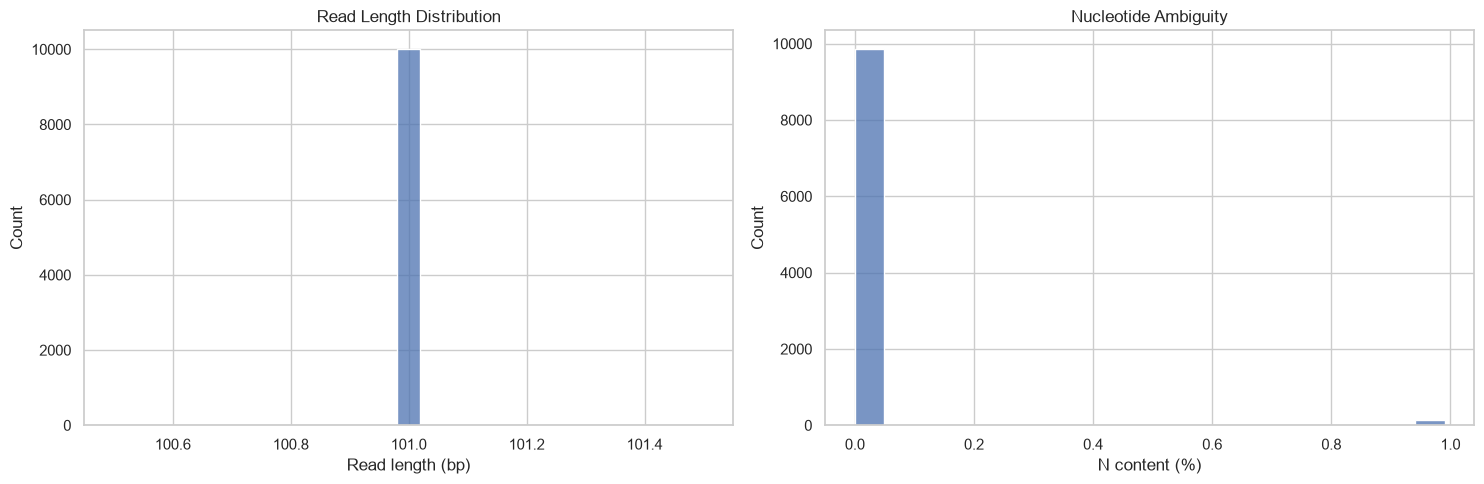

In [13]:
# CELL 12 — Analyze read length and ambiguous nucleotide content
# Bu cell read uzunluqlarını və N nucleotide faizini vizuallaşdırır.

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    lengths,
    bins=25,
    ax=axes[0]
)

axes[0].set_title("Read Length Distribution")
axes[0].set_xlabel("Read length (bp)")

sns.histplot(
    n_percent,
    bins=20,
    ax=axes[1]
)

axes[1].set_title("Nucleotide Ambiguity")
axes[1].set_xlabel("N content (%)")

plt.tight_layout()
plt.show()

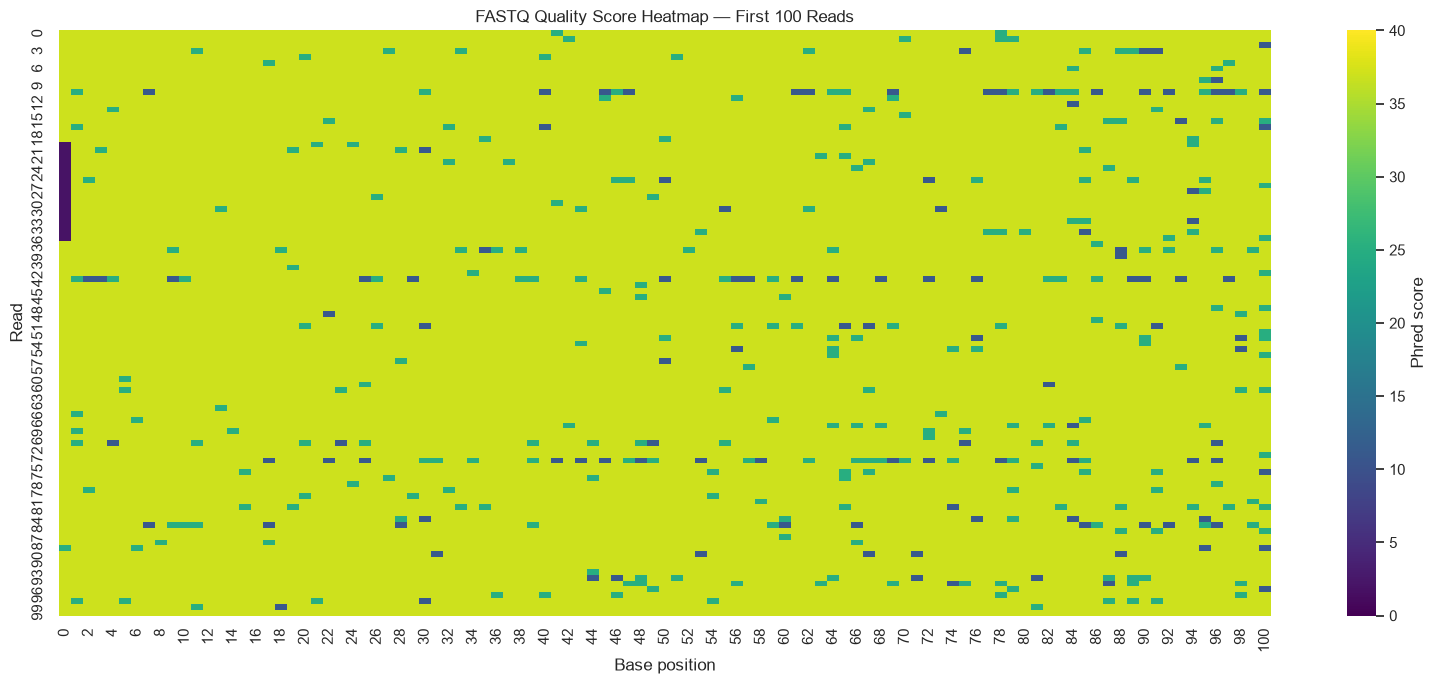

In [14]:
# CELL 13 — Generate FASTQ quality heatmap
# Bu cell ilk 100 read üçün hər nucleotide mövqeyinin Phred score səviyyəsini göstərir.

plt.figure(figsize=(16, 7))

sns.heatmap(
    quality_matrix[:100, :],
    cmap="viridis",
    vmin=0,
    vmax=40,
    cbar_kws={"label": "Phred score"}
)

plt.title("FASTQ Quality Score Heatmap — First 100 Reads")
plt.xlabel("Base position")
plt.ylabel("Read")

plt.tight_layout()
plt.show()

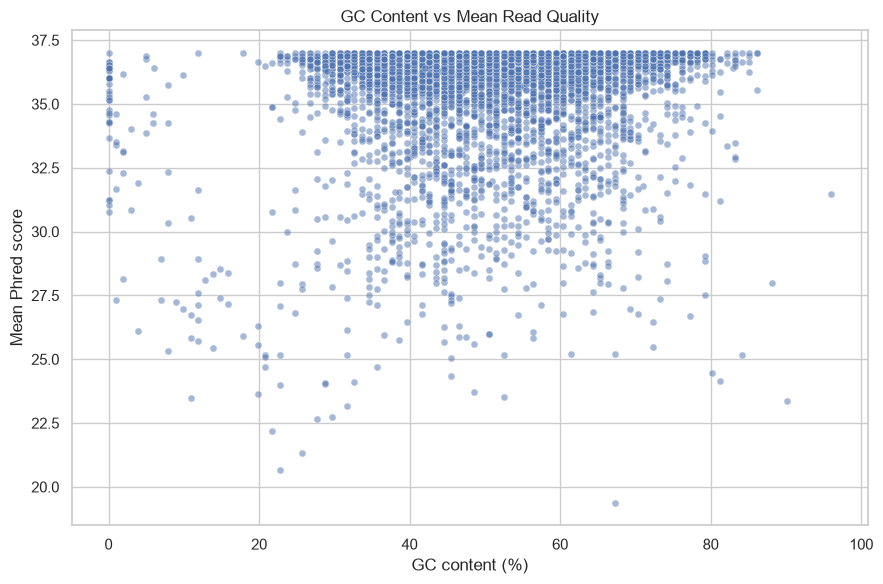

In [15]:
# CELL 14 — Investigate GC content versus sequencing quality
# Bu cell read-lərin GC faizi ilə orta Phred keyfiyyəti arasındakı əlaqəni göstərir.

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=gc_percent,
    y=mean_q,
    alpha=0.5,
    s=25
)

plt.title("GC Content vs Mean Read Quality")
plt.xlabel("GC content (%)")
plt.ylabel("Mean Phred score")

plt.tight_layout()
plt.show()

In [16]:
# CELL 15 — Final analysis report
# Bu cell analiz nəticələrinin qısa yekununu çap edir.

print("=" * 55)
print("CANCER RNA-seq QUALITY CONTROL REPORT")
print("=" * 55)

print("Dataset accession:", ACCESSION)
print("FASTQ file analyzed: R1 / first FASTQ")
print("Reads analyzed:", len(records))
print("Mean read length:", round(lengths.mean(), 2), "bp")
print("Mean Phred score:", round(all_q.mean(), 2))
print("Q20 bases:", round(100 * np.mean(all_q >= 20), 2), "%")
print("Q30 bases:", round(100 * np.mean(all_q >= 30), 2), "%")
print("Mean GC content:", round(gc_percent.mean(), 2), "%")
print("Mean N content:", round(n_percent.mean(), 4), "%")

print("=" * 55)
print("ANALYSIS COMPLETED")
print("Source: ENA / SRA")
print("Accession:", ACCESSION)
print("=" * 55)

CANCER RNA-seq QUALITY CONTROL REPORT
Dataset accession: ERR15159018
FASTQ file analyzed: R1 / first FASTQ
Reads analyzed: 10000
Mean read length: 101.0 bp
Mean Phred score: 36.06
Q20 bases: 98.01 %
Q30 bases: 94.52 %
Mean GC content: 51.1 %
Mean N content: 0.0146 %
ANALYSIS COMPLETED
Source: ENA / SRA
Accession: ERR15159018
